| Inicio | Anterior | Siguiente |
| --- | --- | --- |
| [🏠](../README.md) | [⏪](../17_DATA_ASSIMILATION/17_1_DATA_ASSIMILATION.ipynb) | [⏩](../18_HPC_COMPUTACION_CIENTIFICA/18_2_GPU.ipynb) |

# 18.1 PERFORMANCE EN COMPUTACIÓN CIENTÍFICA

Una implementación científica debe producir una respuesta fiable en un tiempo y memoria razonables. Antes de comprar más hardware conviene entender qué operaciones consumen recursos y qué error introduce el algoritmo. En este cuaderno mediremos implementaciones equivalentes, estudiaremos memoria y construiremos una comparación entre costo y precisión.

**Objetivos.** Medir tiempos correctamente, interpretar complejidad, vectorizar sin perder significado y reconocer cuándo el tamaño de un arreglo domina el costo. Requisitos: NumPy, álgebra lineal y errores numéricos. Bibliotecas: NumPy, SciPy, Matplotlib y herramientas estándar. Los tiempos serán los del equipo que ejecuta el cuaderno; no se fijan ganancias esperadas.

## 1. Tiempo, memoria y precisión son objetivos distintos

El tiempo total de un experimento puede escribirse como $T=T_{\text{datos}}+T_{\text{solver}}+T_{\text{entrenamiento}}+T_{\text{evaluación}}$. Optimizar una parte pequeña apenas cambia el total. La memoria pico incluye datos, temporales, parámetros, gradientes y buffers; no basta con mirar el tamaño final del resultado.

Una operación rápida que cambia la ecuación o reduce precisión de manera injustificada no es una mejora científica. Compararemos salidas primero y luego tiempos. En SciML es especialmente importante mantener iguales condiciones iniciales, puntos de evaluación, tolerancias y tipos numéricos.

## 2. Un problema concreto: términos de una pérdida física

Supongamos que evaluamos $r_i=u_i^2+\sin(u_i)-b_i$ y una pérdida $L=N^{-1}\sum_i r_i^2$. Puede representar una pieza elemental de una pérdida sobre muchos puntos de colocación. Una versión usa un bucle Python; otra realiza operaciones sobre todo el arreglo.

Ambas hacen $O(N)$ operaciones. Vectorizar no cambia ese orden: cambia dónde corre el bucle y su costo constante. La versión NumPy usa rutinas compiladas; además crea varios temporales. Para un arreglo enorme podría importar más evitar temporales que eliminar el bucle Python.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from time import perf_counter
import cProfile, pstats, io
from scipy.linalg import solve_triangular
rng = np.random.default_rng(181)
plt.rcParams.update({"figure.figsize": (8, 4), "axes.grid": True, "font.size": 11})

def perdida_bucle(u, b):
    total = 0.0
    for ui, bi in zip(u, b):
        residual = ui*ui + np.sin(ui) - bi
        total += residual*residual
    return total/len(u)

def perdida_numpy(u, b):
    residual = u*u + np.sin(u) - b
    return np.mean(residual*residual)

u = rng.normal(size=20000); b = rng.normal(size=u.size)
print("Pérdida bucle:", perdida_bucle(u, b), "NumPy:", perdida_numpy(u, b))
assert np.allclose(perdida_bucle(u, b), perdida_numpy(u, b), rtol=1e-12)

Pérdida bucle: 4.430279895741915 NumPy: 4.4302798957419265


## 3. Diseñar una medición reproducible

Usaremos `perf_counter`, calentamiento y varias repeticiones. La mediana reduce el efecto de interrupciones aisladas, aunque no elimina sesgos por carga del sistema, frecuencia del procesador, caché o multihilo interno. Separaremos creación de datos y operación medida.

El temporizador mide tiempo transcurrido, no exclusivamente uso de CPU. Un resultado pequeño puede estar dominado por la resolución y el overhead. Para comparar métodos, conviene intercalar o aleatorizar el orden, repetir tamaños y registrar versiones. No redondearemos antes de calcular razones.

En una GPU las operaciones pueden ser asíncronas: el patrón de temporización necesita sincronización, como estudiaremos en el siguiente cuaderno.

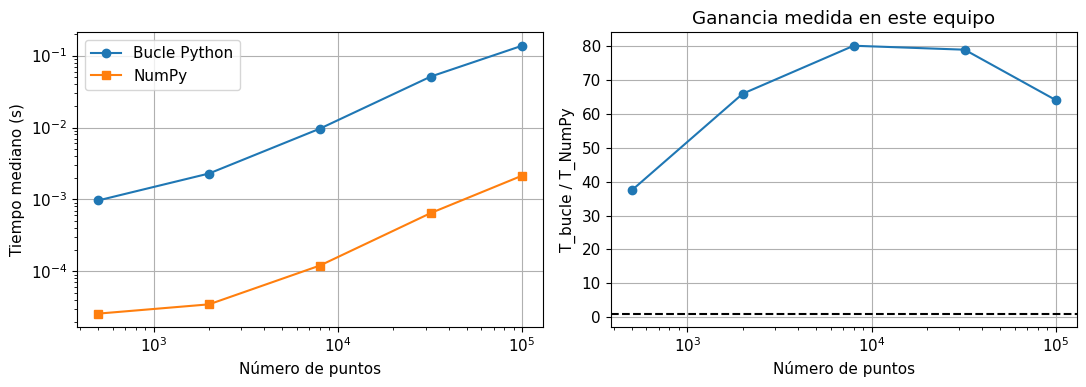

In [2]:
def medir(func, repeticiones=5):
    func()  # Calentamiento fuera de la medición.
    tiempos = []
    for _ in range(repeticiones):
        inicio = perf_counter(); func(); tiempos.append(perf_counter()-inicio)
    return np.median(tiempos), np.min(tiempos), np.max(tiempos)

tamanos = np.array([500, 2000, 8000, 32000, 100000])
t_bucle, t_np = [], []
for n in tamanos:
    un = rng.normal(size=n); bn = rng.normal(size=n)
    tb = medir(lambda: perdida_bucle(un, bn), 3)[0]
    tn = medir(lambda: perdida_numpy(un, bn), 7)[0]
    t_bucle.append(tb); t_np.append(tn)
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].loglog(tamanos, t_bucle, "o-", label="Bucle Python")
axes[0].loglog(tamanos, t_np, "s-", label="NumPy")
axes[0].set(xlabel="Número de puntos", ylabel="Tiempo mediano (s)"); axes[0].legend()
axes[1].semilogx(tamanos, np.array(t_bucle)/np.array(t_np), "o-")
axes[1].axhline(1, color="k", ls="--")
axes[1].set(xlabel="Número de puntos", ylabel="T_bucle / T_NumPy", title="Ganancia medida en este equipo")
plt.tight_layout(); plt.show()

**Interpretación.** Una tendencia aproximadamente lineal en la figura log-log es compatible con trabajo $O(N)$; pequeños tamaños muestran overhead. La razón de tiempos es una medida local del equipo, no una propiedad matemática del lenguaje ni una promesa para otros cálculos. El bucle y la reducción vectorizada pueden acumular en distinto orden y diferir en los últimos bits.

## 4. Perfilar antes de modificar

Un perfilador atribuye tiempo y número de llamadas a funciones. Su propio overhead puede alterar operaciones pequeñas, por lo que sirve para localizar cuellos de botella; una medición independiente sirve para cuantificar la mejora.

La siguiente salida permite comprobar si el tiempo se concentra en el bucle y sus llamadas. Si una rutina llama miles de veces a una función barata, reducir el número de llamadas puede ser más útil que retocar esa función. Si domina una factorización, cambiar la estructura algebraica puede superar cualquier microoptimización.

In [3]:
perfil = cProfile.Profile()
perfil.enable()
for _ in range(3):
    perdida_bucle(u, b)
    perdida_numpy(u, b)
perfil.disable()
salida = io.StringIO()
pstats.Stats(perfil, stream=salida).sort_stats("cumulative").print_stats(8)
print(salida.getvalue())
print("NumPy:", np.__version__)
print("Memoria de u (MiB):", u.nbytes/2**20)

         80 function calls in 0.090 seconds

   Ordered by: cumulative time
   List reduced from 30 to 8 due to restriction <8>

   ncalls  tottime  percall  cumtime  percall filename:lineno(function)
        2    0.000    0.000    0.090    0.045 /tmp/sciml-venv/lib/python3.10/site-packages/IPython/core/interactiveshell.py:3543(run_code)
        2    0.000    0.000    0.090    0.045 {built-in method builtins.exec}
        1    0.000    0.000    0.090    0.090 <ipython-input-1-6fb0976cb24f>:1(<module>)
        3    0.088    0.029    0.089    0.030 <ipython-input-1-a54dae439adb>:9(perdida_bucle)
        3    0.001    0.000    0.001    0.000 <ipython-input-1-a54dae439adb>:16(perdida_numpy)
        3    0.000    0.000    0.000    0.000 /tmp/sciml-venv/lib/python3.10/site-packages/numpy/_core/fromnumeric.py:3735(mean)
        3    0.000    0.000    0.000    0.000 /tmp/sciml-venv/lib/python3.10/site-packages/numpy/_core/_methods.py:118(_mean)
        2    0.000    0.000    0.000    0.000 /us

## 5. Broadcasting: útil, pero no gratuito

Para puntos $x_i\in\mathbb R^d$, la matriz de distancias cuadradas es $D_{ij}=\sum_\ell(x_{i\ell}-x_{j\ell})^2$. La expresión `X[:,None,:]-X[None,:,:]` forma un temporal de tamaño $N^2d$. Broadcasting evita copiar algunas entradas, pero **el resultado de la resta sí ocupa memoria**.

Otra identidad es $D_{ij}=\|x_i\|^2+\|x_j\|^2-2x_i^Tx_j$. Reduce el temporal de dimensión tres, aunque puede introducir cancelación cuando los puntos son casi idénticos. Para cantidades agregadas podemos calcular bloques y no almacenar toda la matriz. Si realmente necesitamos todos los pares, la salida sigue costando $O(N^2)$.

Distancia cuadrada media: 6.227526130434025
Tiempo broadcasting: 0.06357918600042467
Tiempo bloques: 0.026007833999756258


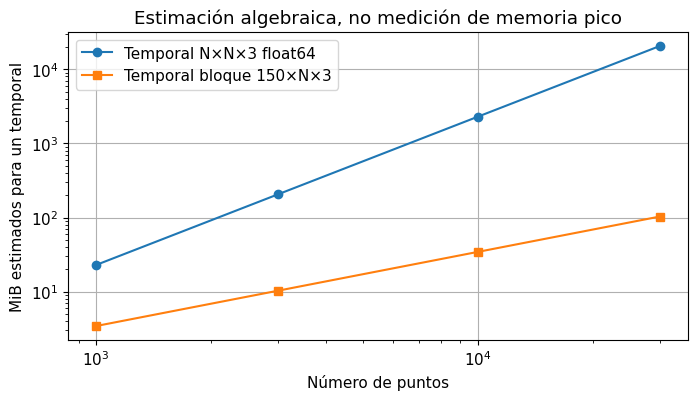

In [4]:
X = rng.normal(size=(1200, 3))

def media_distancias_broadcast(X):
    return np.sum((X[:, None, :]-X[None, :, :])**2, axis=2).mean()

def media_distancias_bloques(X, bloque=150):
    total = 0.0
    for inicio in range(0, len(X), bloque):
        diferencias = X[inicio:inicio+bloque, None, :]-X[None, :, :]
        total += np.sum(diferencias*diferencias)
    return total/len(X)**2

v1 = media_distancias_broadcast(X)
v2 = media_distancias_bloques(X)
assert np.allclose(v1, v2, rtol=1e-12)
print("Distancia cuadrada media:", v1)
print("Tiempo broadcasting:", medir(lambda: media_distancias_broadcast(X), 3)[0])
print("Tiempo bloques:", medir(lambda: media_distancias_bloques(X), 3)[0])
ns = np.array([1000, 3000, 10000, 30000])
fig, ax = plt.subplots()
ax.loglog(ns, ns**2*3*8/2**20, "o-", label="Temporal N×N×3 float64")
ax.loglog(ns, 150*ns*3*8/2**20, "s-", label="Temporal bloque 150×N×3")
ax.set(xlabel="Número de puntos", ylabel="MiB estimados para un temporal", title="Estimación algebraica, no medición de memoria pico")
ax.legend(); plt.show()

## 6. Qué representa la estimación de memoria

La figura calcula elementos por bytes, sin reservar los tamaños grandes. No es una medida de memoria pico: en la expresión completa pueden coexistir resta, cuadrado y suma, además de los datos originales y el allocator. Una GPU puede agotar memoria antes de alcanzar el tamaño que sugiere un solo arreglo.

El cálculo por bloques intercambia más llamadas por un temporal menor. Puede ser más rápido o más lento, dependiendo de caché y tamaños. En un kernel de un neural operator o en distancias para Gaussian processes, esta elección puede decidir si el problema cabe en el equipo.

## 7. Evitar trabajo repetido: factorizar una vez

Si $A x_j=b_j$ para muchos $b_j$ y $A$ es fija, conviene factorizar $A$ una vez. Para una matriz simétrica positiva definida, $A=LL^T$ y luego cada solución requiere dos sustituciones triangulares. La factorización densa cuesta $O(n^3)$; cada lado derecho, $O(n^2)$.

No hay razón para formar $A^{-1}$: resolver sistemas suele requerir menos trabajo y evitar errores adicionales. Además, antes de usar Cholesky hay que verificar que la estructura matemática justifique simetría y positividad; no debemos forzarla sobre cualquier matriz.

In [5]:
n, lados = 140, 24
Z = rng.normal(size=(n, n)); Amat = Z.T @ Z + 2*np.eye(n)
Bmat = rng.normal(size=(n, lados))
L = np.linalg.cholesky(Amat)

def resolver_repetido():
    return np.column_stack([np.linalg.solve(Amat, Bmat[:, j]) for j in range(lados)])

def resolver_factorizado():
    inter = solve_triangular(L, Bmat, lower=True)
    return solve_triangular(L.T, inter, lower=False)

xf = resolver_factorizado(); xr = resolver_repetido()
residual_rel = np.linalg.norm(Amat @ xf-Bmat)/np.linalg.norm(Bmat)
assert np.allclose(xf, xr, rtol=1e-9, atol=1e-9)
print("Residual relativo:", residual_rel)
print("Soluciones independientes (s):", medir(resolver_repetido, 3)[0])
print("Reutilizar Cholesky (s, factor fuera):", medir(resolver_factorizado, 3)[0])
print("Factorización sola (s):", medir(lambda: np.linalg.cholesky(Amat), 3)[0])

Residual relativo: 7.586766957394511e-15
Soluciones independientes (s): 0.0049309779969917145
Reutilizar Cholesky (s, factor fuera): 8.992899893200956e-05
Factorización sola (s): 0.00013152700194041245


## 8. Una comparación debe explicar qué incluye

La medición de reutilizar Cholesky excluye la factorización, y por eso debe informarse también ese costo. Si solo hay un lado derecho, la conclusión puede cambiar. Si $A$ varía en cada iteración, no se puede reutilizar sin justificar una actualización.

La biblioteca de álgebra lineal puede usar varios hilos. Al paralelizar por fuera hay riesgo de lanzar muchos hilos dentro de cada tarea y sobresuscribir núcleos. El tamaño pequeño de este ejemplo permite estudiar el patrón sin convertir el cuaderno en un benchmark de larga duración.

## 9. Costo frente a precisión: un solver físico

Consideremos $u'=-u$, $u(0)=1$, cuya solución en $T=2$ es $e^{-2}$. Euler explícito da $u_{n+1}=(1-h)u_n$ y error global de primer orden. Heun usa una predicción y promedia pendientes, con error global de segundo orden para esta ecuación suave.

Reducir el tiempo no es el único objetivo: necesitamos saber qué método alcanza un error dado con menor costo. Mediremos ambos y representaremos error frente a paso y frente a tiempo. Los tiempos pequeños son sensibles al overhead; las pendientes de error ofrecen una referencia matemática independiente.

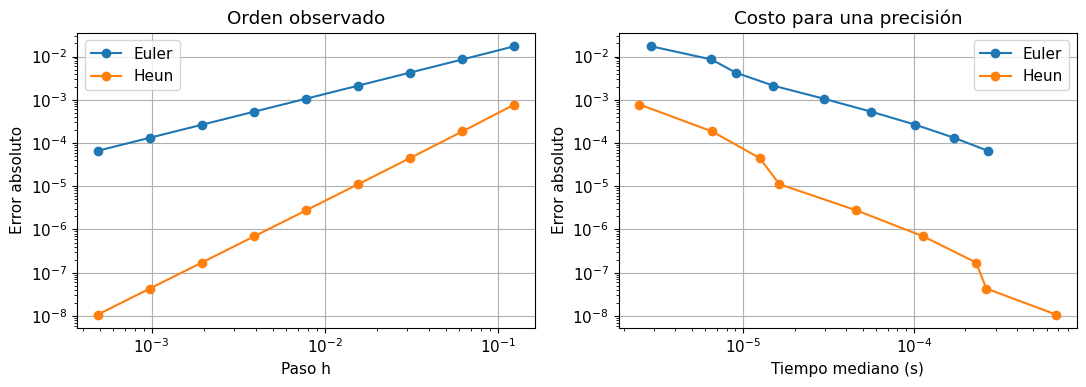

In [6]:
def integrar(N, metodo):
    h = 2.0/N; valor = 1.0
    for _ in range(N):
        if metodo == "Euler":
            valor *= 1-h
        else:
            k1 = -valor; k2 = -(valor+h*k1)
            valor += 0.5*h*(k1+k2)
    return valor

Ns = 2**np.arange(4, 13)
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for metodo in ["Euler", "Heun"]:
    errores, tiempos = [], []
    for N in Ns:
        errores.append(abs(integrar(int(N), metodo)-np.exp(-2)))
        tiempos.append(medir(lambda: integrar(int(N), metodo), 5)[0])
    axes[0].loglog(2/Ns, errores, "o-", label=metodo)
    axes[1].loglog(tiempos, errores, "o-", label=metodo)
axes[0].set(xlabel="Paso h", ylabel="Error absoluto", title="Orden observado")
axes[1].set(xlabel="Tiempo mediano (s)", ylabel="Error absoluto", title="Costo para una precisión")
for ax in axes: ax.legend()
plt.tight_layout(); plt.show()

## 10. Complejidad y escalabilidad

La notación $O(N)$ describe una cota asintótica, no un tiempo exacto. Dos algoritmos del mismo orden pueden tener constantes muy distintas; uno de orden peor puede ganar para tamaños pequeños. Una red densa, una FFT y un método de diferencias finitas requieren patrones de memoria distintos, aunque todos puedan vectorizarse.

En HPC distinguimos strong scaling, que mantiene fijo el problema y aumenta recursos, de weak scaling, que aumenta el problema junto con los recursos. Comunicación, sincronización y movimiento de datos pueden dominar aunque el cómputo local sea rápido.

## 11. Ley de Amdahl

Si una fracción $s$ del tiempo es serial y el resto se paraleliza perfectamente en $p$ recursos,
$$S(p)\le\frac{1}{s+(1-s)/p}.$$
Con $s=0.1$, incluso infinitos recursos dan como máximo una aceleración de diez. La fórmula idealiza comunicación y balance: en la práctica suelen reducir más la ganancia. Perfilar ayuda a identificar qué parte limita el objetivo final.

## 12. Aplicación a SciML

En entrenamiento, el costo puede venir de crear datos con un solver, evaluar derivadas automáticas, cargar minibatches o validar condiciones físicas. Conviene medir el experimento completo y una sección específica. Para PINNs, pedir derivadas de segundo orden cambia el grafo y la memoria; para neural operators, el tamaño de la malla y el número de modos altera el costo.

No uses el tiempo de inferencia de una red como si incluyera generación de datos y entrenamiento. Una comparación de costo científico debe decir si el modelo se utiliza una vez o miles de veces y qué precisión alcanza en casos nuevos.

## 13. Reglas prácticas y límites del cuaderno

Primero establece una referencia numérica, después perfila, cambia una cosa y repite con entradas iguales. Guarda la distribución de tiempos si las diferencias son pequeñas. Los benchmarks anteriores no certifican rendimiento para otro hardware; sí enseñan a formular una comparación revisable.

`nbytes` no incluye metadatos ni todos los temporales. Un residual pequeño no implica error de solución pequeño si la matriz está mal condicionada. Y una ejecución rápida de una función aislada no garantiza una aplicación rápida cuando dominan lectura o comunicación.


| Inicio | Anterior | Siguiente |
| --- | --- | --- |
| [🏠](../README.md) | [⏪](../17_DATA_ASSIMILATION/17_1_DATA_ASSIMILATION.ipynb) | [⏩](../18_HPC_COMPUTACION_CIENTIFICA/18_2_GPU.ipynb) |